# LAB 3
En este lab repasaremos los conceptos vistos en la clase 4 Frontera Eficiente

## Bibliotecas a importar

* yfinance: la usaremos para descargar información
* numpy: la usaremos para realizar diversas operaciones matemáticas
* pandas: la usaremos para realizar cálculos con vectores
* analisis_portafolios: nuestra biblioteca del curso que tendrá funciones para los procedimientos vistos en clase

In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import analisis_portafolios as ap

## Descargamos la información a analizar
En este lab trabajaremos con varias empresas de sectores distintos, pues queremos estudiar cómo se comportan juntas.

In [2]:
tickers = ["AAPL", "MSFT", "JPM", "KO", "XOM"] # tickers de las acciones a analizar
fecha_inicio = "2025-01-01" # fecha de inicio para descargar
fecha_fin = "2025-12-31" # fecha final para descargar

In [3]:
datos = yf.download(tickers, start=fecha_inicio, end=fecha_fin)

[*********************100%***********************]  5 of 5 completed


In [4]:
# extraemos los precios de cierre de todas las empresas
precios_cierre = datos["Close"]
precios_cierre.head()

Ticker,AAPL,JPM,KO,MSFT,XOM
Date,,,,,
2025-01-02,242.093140,230.583786,58.923302,412.895325,101.475349
2025-01-03,241.606659,233.735092,58.837547,417.600586,101.995445
2025-01-06,243.234848,232.595551,57.941883,422.039490,101.881966
2025-01-07,240.464966,234.836029,57.970459,416.633850,102.837051
2025-01-08,240.951385,234.797409,58.799427,418.794189,101.116013


<Axes: xlabel='Date'>

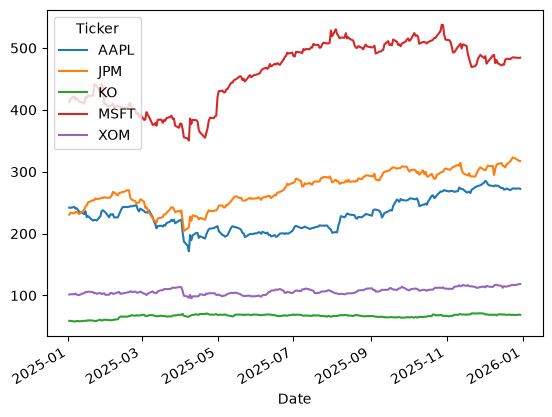

In [5]:
# visualizamos los precios de cierre
precios_cierre.plot()

## Rendimientos

Calculamos los rendimientos porcentuales igual que en los labs anteriores. Ahora obtenemos una columna por empresa.

In [6]:
rend_simple = precios_cierre.pct_change().dropna()

In [7]:
rend_simple.head()

Ticker,AAPL,JPM,KO,MSFT,XOM
Date,,,,,
2025-01-03,-0.002009,0.013667,-0.001455,0.011396,0.005125
2025-01-06,0.006739,-0.004875,-0.015223,0.010630,-0.001113
2025-01-07,-0.011388,0.009633,0.000493,-0.012808,0.009374
2025-01-08,0.002023,-0.000164,0.014300,0.005185,-0.016736
2025-01-10,-0.024104,-0.013409,-0.010371,-0.013214,-0.003647


## Riesgo y rendimiento por activo

Las funciones del Lab 1 también funcionan con varias columnas a la vez: nos regresan un valor por empresa.

In [8]:
# rendimiento esperado anualizado de cada activo
rend_esperado = ap.rendimiento_anualizado(rend_simple)
rend_esperado

Ticker
AAPL    0.127072
JPM     0.383215
KO      0.169417
MSFT    0.176222
XOM     0.171806
dtype: float64

In [9]:
# volatilidad anualizada de cada activo
ap.volatilidad_anualizada(rend_simple)

Ticker
AAPL    0.325256
JPM     0.249451
KO      0.175680
MSFT    0.243322
XOM     0.234977
dtype: float64

## Covarianza y correlación

La **covarianza** mide cómo se mueven juntos los rendimientos de dos activos:

$$ \sigma_{AB} = \frac{1}{n-1}\sum_{t=1}^{n}(R_{A,t}-\bar{R}_A)(R_{B,t}-\bar{R}_B) $$

La **correlación** es la covarianza estandarizada, por lo que siempre está entre $-1$ y $1$:

$$ \rho_{AB} = \frac{\sigma_{AB}}{\sigma_A \, \sigma_B} $$

### Matriz de covarianzas
Al igual que la volatilidad, la covarianza se anualiza multiplicando por $p=252$.

In [10]:
cov = ap.matriz_covarianza_anualizada(rend_simple)
cov

Ticker,AAPL,JPM,KO,MSFT,XOM
Ticker,,,,,
AAPL,0.105791,0.041698,0.006111,0.038464,0.029098
JPM,0.041698,0.062226,0.003744,0.028786,0.020908
KO,0.006111,0.003744,0.030863,-0.005780,0.005234
MSFT,0.038464,0.028786,-0.005780,0.059205,0.010341
XOM,0.029098,0.020908,0.005234,0.010341,0.055214


**NOTA:** La diagonal de la matriz de covarianzas es la varianza anualizada de cada activo, es decir, la volatilidad anualizada al cuadrado.

In [11]:
# comprobamos: la raíz de la diagonal es la volatilidad anualizada
np.sqrt(np.diag(cov))

array([0.32525603, 0.24945113, 0.17567973, 0.24332173, 0.23497746])

### Matriz de correlación

In [12]:
rend_simple.corr()

Ticker,AAPL,JPM,KO,MSFT,XOM
Ticker,,,,,
AAPL,1.000000,0.513925,0.106953,0.486008,0.380720
JPM,0.513925,1.000000,0.085431,0.474251,0.356690
KO,0.106953,0.085431,1.000000,-0.135209,0.126780
MSFT,0.486008,0.474251,-0.135209,1.000000,0.180869
XOM,0.380720,0.356690,0.126780,0.180869,1.000000


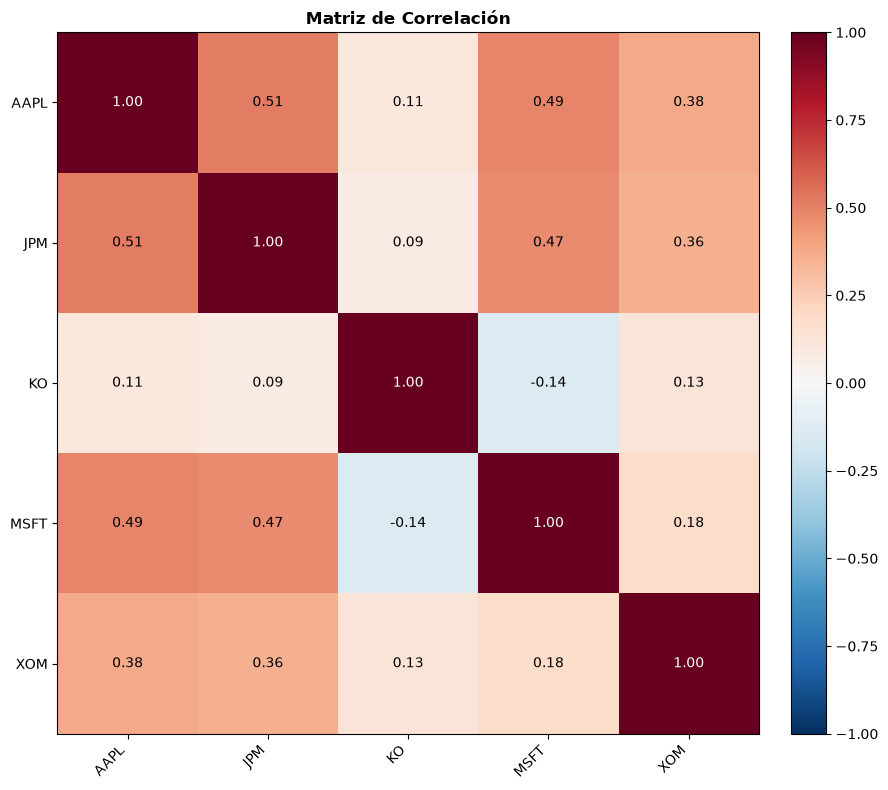

In [13]:
# Visualizamos
fig, ax = ap.plot_correlacion(rend_simple)

Entre menor sea la correlación entre dos activos, mayor será el beneficio de combinarlos en un portafolio (**efecto diversificación**).

## Portafolio de dos activos

Si invertimos una proporción $w_1$ en el activo 1 y $w_2 = 1 - w_1$ en el activo 2:

$$ \mu_p = w_1 \mu_1 + w_2 \mu_2 $$

$$ \sigma_p^2 = w_1^2\sigma_1^2 + w_2^2\sigma_2^2 + 2w_1w_2\sigma_{12} $$

En forma matricial, para cualquier número de activos:

$$ \mu_p = w^\top \mu \qquad \sigma_p = \sqrt{w^\top \Sigma \, w} $$

In [33]:
# elegimos dos activos
activos_2 = ["KO", "MSFT"]
rend_esperado_2 = rend_esperado[activos_2]
cov_2 = cov.loc[activos_2, activos_2]

In [34]:
# portafolio 50/50
pesos_50 = np.array([0.5, 0.5])
print(f"Rendimiento: {ap.rendimiento_portafolio(pesos_50, rend_esperado_2):.2%}")
print(f"Volatilidad: {ap.volatilidad_portafolio(pesos_50, cov_2):.2%}")

Rendimiento: 17.28%
Volatilidad: 14.01%


Comparemos contra la volatilidad de cada activo por separado. La volatilidad del portafolio es menor que el promedio de las volatilidades individuales porque la correlación es menor a 1.

In [35]:
vol_2 = np.sqrt(np.diag(cov_2))
print(f"Promedio de volatilidades individuales: {vol_2.mean():.2%}")

Promedio de volatilidades individuales: 20.95%


### Frontera de dos activos
Recorremos todas las combinaciones de pesos posibles entre los dos activos.

In [36]:
frontera_2 = ap.frontera_2_activos(rend_esperado_2, cov_2)
frontera_2.head()

,Peso Activo 1,Rendimiento,Volatilidad
0,0.000000,0.176222,0.243322
1,0.020408,0.176083,0.237898
2,0.040816,0.175944,0.232529
3,0.061224,0.175805,0.227220
4,0.081633,0.175666,0.221975


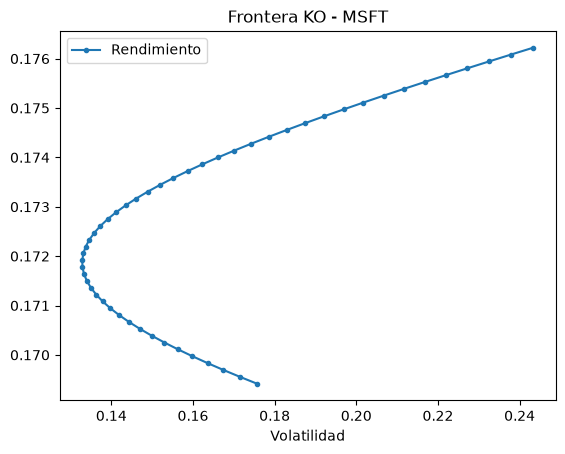

In [37]:
ax = frontera_2.plot(x="Volatilidad", y="Rendimiento", style=".-", title=f"Frontera {activos_2[0]} - {activos_2[1]}")

## Frontera eficiente con N activos

Con más de dos activos existen infinitas combinaciones. Markowitz plantea encontrar, para cada rendimiento objetivo $\mu^*$, el portafolio de **menor volatilidad**:

$$ \min_{w} \; \sqrt{w^\top \Sigma \, w} $$

sujeto a:

$$ w^\top \mu = \mu^* \qquad \sum_i w_i = 1 \qquad 0 \le w_i \le 1 $$

La última restricción significa que **no permitimos ventas en corto**. Este problema se resuelve numéricamente con el optimizador de `scipy`.

In [38]:
frontera = ap.frontera_eficiente(rend_esperado, cov)
frontera.head()

Ticker,Rendimiento,Volatilidad,AAPL,JPM,KO,MSFT,XOM
0,0.180342,0.125177,0.000000e+00,0.040780,0.525723,0.265119,0.168379
1,0.184482,0.125247,0.000000e+00,0.060458,0.519438,0.257218,0.162887
2,0.188622,0.125452,1.368128e-17,0.080184,0.514917,0.247973,0.156926
3,0.192763,0.125789,1.077426e-18,0.099911,0.510382,0.238703,0.151004
4,0.196903,0.126258,0.000000e+00,0.119637,0.505848,0.229432,0.145083


In [20]:
# pesos de algunos puntos de la frontera
frontera.iloc[::10].round(3)

Ticker,Rendimiento,Volatilidad,AAPL,JPM,KO,MSFT,XOM
0,0.180,0.125,0.0,0.041,0.526,0.265,0.168
10,0.222,0.132,0.0,0.238,0.479,0.174,0.110
20,0.263,0.150,0.0,0.435,0.432,0.081,0.051
30,0.305,0.175,0.0,0.632,0.368,0.000,0.000
40,0.346,0.211,0.0,0.826,0.174,0.000,0.000


## Portafolio de Mínima Varianza Global (GMV)
Es el portafolio de la frontera con la menor volatilidad posible, sin importar su rendimiento.

In [21]:
pesos_gmv = ap.portafolio_minima_varianza(cov)
pd.Series(pesos_gmv, index=rend_esperado.index).round(4)

Ticker
AAPL    0.0000
JPM     0.0407
KO      0.5238
MSFT    0.2669
XOM     0.1686
dtype: float64

In [22]:
print(f"Rendimiento GMV: {ap.rendimiento_portafolio(pesos_gmv, rend_esperado):.2%}")
print(f"Volatilidad GMV: {ap.volatilidad_portafolio(pesos_gmv, cov):.2%}")

Rendimiento GMV: 18.03%
Volatilidad GMV: 12.52%


## Portafolio de Máximo Sharpe y CML

Si existe un activo libre de riesgo, la mejor combinación es la que maximiza el Ratio de Sharpe (**portafolio tangente**):

$$ \max_{w} \; \frac{w^\top \mu - r_f}{\sqrt{w^\top \Sigma \, w}} $$

La recta que une a $r_f$ con este portafolio es la **Línea del Mercado de Capitales (CML)**.

In [23]:
# asumimos tasa libre de riesgo igual a 0.07
rf = 0.07
pesos_msr = ap.portafolio_max_sharpe(rend_esperado, cov, rf)
pd.Series(pesos_msr, index=rend_esperado.index).round(4)

Ticker
AAPL    0.0000
JPM     0.6497
KO      0.3503
MSFT    0.0000
XOM     0.0000
dtype: float64

In [24]:
rend_msr = ap.rendimiento_portafolio(pesos_msr, rend_esperado)
vol_msr = ap.volatilidad_portafolio(pesos_msr, cov)
print(f"Rendimiento: {rend_msr:.2%}")
print(f"Volatilidad: {vol_msr:.2%}")
print(f"Sharpe: {(rend_msr - rf) / vol_msr:.3f}")

Rendimiento: 30.83%
Volatilidad: 17.82%
Sharpe: 1.337


**NOTA:** Si ningún activo tiene un rendimiento esperado mayor a la tasa libre de riesgo, el portafolio de máximo Sharpe no tiene sentido económico: convendría invertir todo en el activo libre de riesgo.

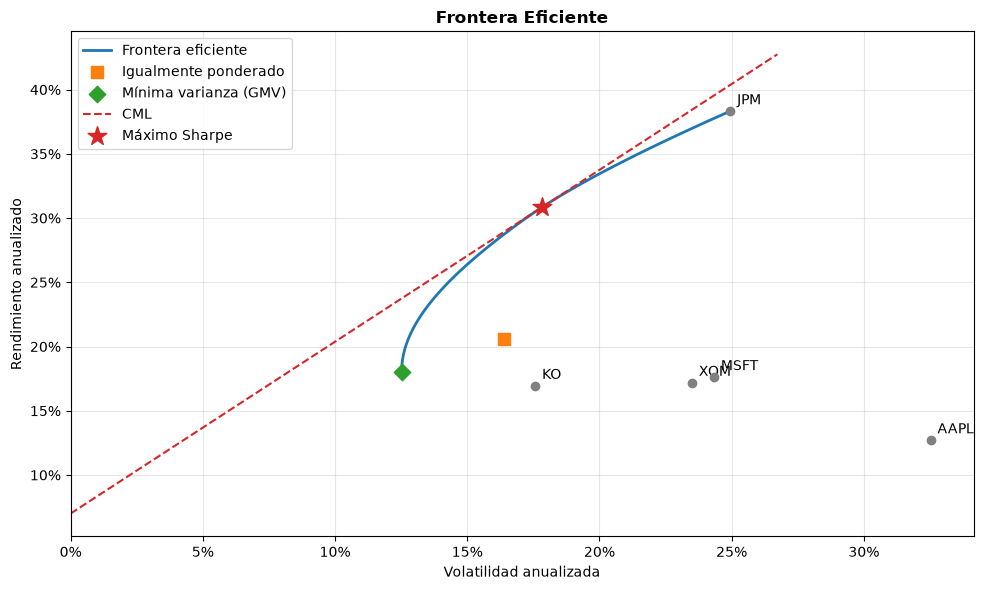

In [25]:
# Visualizamos todo junto
fig, ax = ap.plot_frontera_eficiente(rend_esperado, cov, tasa_libre_de_riesgo=rf)

## Comparación de portafolios

Comparemos tres portafolios: igualmente ponderado (EW), mínima varianza (GMV) y máximo Sharpe (MSR).

Con `rendimientos_historicos_portafolio` construimos la serie diaria de rendimientos de cada portafolio y así podemos reutilizar las funciones de los Labs 1 y 2.

In [26]:
n = len(rend_esperado)
pesos_ew = np.repeat(1 / n, n)

portafolios = {
    "EW": ap.rendimientos_historicos_portafolio(pesos_ew, rend_simple),
    "GMV": ap.rendimientos_historicos_portafolio(pesos_gmv, rend_simple),
    "MSR": ap.rendimientos_historicos_portafolio(pesos_msr, rend_simple),
}
rend_portafolios = pd.DataFrame(portafolios)
rend_portafolios.head()

,EW,GMV,MSR
Date,,,
2025-01-03,0.005345,0.003700,0.008370
2025-01-06,-0.000768,-0.005523,-0.008500
2025-01-07,-0.000939,-0.001186,0.006431
2025-01-08,0.000922,0.006045,0.004902
2025-01-10,-0.012949,-0.010119,-0.012345


In [27]:
comparacion = pd.DataFrame({
    "Rendimiento": ap.rendimiento_anualizado(rend_portafolios),
    "Volatilidad": ap.volatilidad_anualizada(rend_portafolios),
    "Sharpe": ap.sharpe_ratio(rend_portafolios, rf),
    "Max Drawdown": [ap.max_drawdown(rend_portafolios[c])[0] for c in rend_portafolios],
    "VaR 95%": [ap.var_historic(rend_portafolios[c]) for c in rend_portafolios],
    "CVaR 95%": ap.cvar_historic(rend_portafolios),
})
comparacion.round(4)

,Rendimiento,Volatilidad,Sharpe,Max Drawdown,VaR 95%,CVaR 95%
EW,0.2239,0.1638,0.9398,-0.1548,0.0137,0.0223
GMV,0.1962,0.1252,1.0085,-0.0747,0.0093,0.0147
MSR,0.3170,0.1782,1.3859,-0.1611,0.0122,0.0270


**NOTA:** Los portafolios fueron optimizados con los mismos datos con los que los evaluamos (*in-sample*), por eso el MSR luce tan bien. En la práctica los rendimientos esperados son muy difíciles de estimar y el desempeño fuera de muestra suele ser peor.

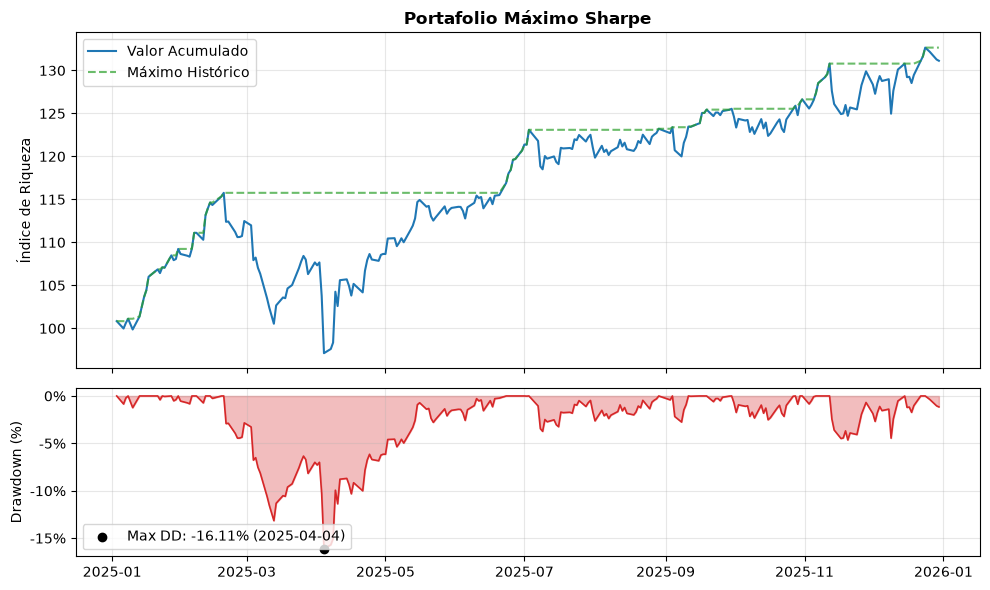

In [28]:
# Visualizamos el drawdown del portafolio de máximo Sharpe
fig, ax = ap.plot_drawdown(rend_portafolios["MSR"], titulo="Portafolio Máximo Sharpe")

## Utilizar funciones con mis propios datos

Si queremos utilizar las funciones con datos capturados manualmente sólo tenemos que escribirlos en el formato adecuado.

Supongamos que tenemos dos activos con los siguientes datos anuales:
* Activo A: rendimiento esperado 10%, volatilidad 15%
* Activo B: rendimiento esperado 6%, volatilidad 8%
* Correlación entre A y B: 0.2

In [29]:
rend_esp_ej = pd.Series([0.10, 0.06], index=["A", "B"])
vol_ej = np.array([0.15, 0.08])
rho = 0.2

In [30]:
# construimos la matriz de covarianzas: cov_AB = rho * vol_A * vol_B
cov_AB = rho * vol_ej[0] * vol_ej[1]
cov_ej = pd.DataFrame(
    [[vol_ej[0]**2, cov_AB],
     [cov_AB, vol_ej[1]**2]],
    index=["A", "B"], columns=["A", "B"]
)
cov_ej

,A,B
A,0.0225,0.0024
B,0.0024,0.0064


In [31]:
# portafolio 60% A, 40% B
pesos_ej = np.array([0.6, 0.4])
print(f"Rendimiento: {ap.rendimiento_portafolio(pesos_ej, rend_esp_ej):.2%}")
print(f"Volatilidad: {ap.volatilidad_portafolio(pesos_ej, cov_ej):.2%}")

Rendimiento: 8.40%
Volatilidad: 10.14%


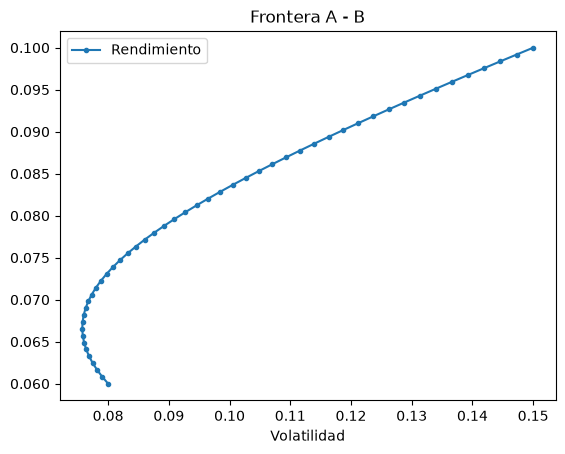

In [32]:
ax = ap.frontera_2_activos(rend_esp_ej, cov_ej).plot(x="Volatilidad", y="Rendimiento", style=".-", title="Frontera A - B")